<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Bayesian Modelling and Causal Inference: Did Job Training Work?

---

### About
One real question runs through this whole notebook: **did a job-training programme increase people's earnings?**

We'll answer it three ways:
- **Gradient descent (Part 2):** how a model actually *learns* its parameters, by walking downhill on a loss function. It's the engine inside regression, logistic regression and neural networks.
- **Bayesian modelling (Parts 3–4):** instead of a single estimate, get a whole **distribution** of plausible effects, and make direct probability statements ("there's a 99% chance the programme helped").
- **Causal inference (Parts 5–6):** when there's **no experiment**, comparing groups can give the wrong answer, even the wrong sign. We'll learn to fix that with **regression adjustment**, **propensity scores**, **matching** and **weighting**.

Part 7 connects them, using Donald Rubin's idea that **a causal question is a missing-data problem**.

### Learning Objectives
- Explain how gradient descent minimises a loss function, implement it, and diagnose learning-rate and scaling problems.
- Explain priors, likelihoods and posteriors, and compute posteriors for a rate and for an average effect.
- Interpret credible intervals and posterior probabilities, and test how much a prior matters.
- Explain potential outcomes, confounding and why randomisation works.
- Estimate a causal effect from observational data with regression, propensity-score matching and inverse-probability weighting, and **check balance**.
- Report a causal effect with honest uncertainty.

### How to use this notebook
- **What to notice** boxes point out the key idea in each output.
- **Check your understanding** questions have answers you can reveal by clicking them.
- 🔎 **Deep dive** sections go further (mini-batch descent, what "95% confidence" means, Ridge as a prior). They're optional when time is short.
- The **methods map** at the end lists every model and method, with the part and visual that shows it.
- The helper functions (`gradient_descent`, `smd_table`, `posterior_normal`, `bayesian_bootstrap`) are written to be reused on any dataset with a treatment, an outcome and some background variables.

# Part 0: Foundations refresher
---
A few ideas from earlier lessons that we'll rely on:

| Idea | Reminder |
|---|---|
| **Derivative (slope)** | How fast a function changes: positive = uphill, negative = downhill, zero = flat (a possible minimum). |
| **Loss function** | Measures how wrong a model is, e.g. mean squared error (MSE) for regression, log-loss for logistic regression. |
| **Conditional probability** | P(A \| B): the probability of A **given** that B happened. |
| **Bayes' theorem** | P(B \| A) = P(A \| B) P(B) / P(A): it "flips" the conditional. |
| **Distributions** | The binomial counts successes; the normal is the bell curve; the **beta** describes a probability between 0 and 1. |
| **Confidence interval** | A range built by a method that captures the true value 95% of the time across repeated samples. |
| **Linear and logistic regression** | Predict a number, or the probability of a 0/1 outcome, from features. |
| **Correlation ≠ causation** | Two things moving together doesn't prove one causes the other. |

# Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
rng = np.random.default_rng(42)

# Part 1: The question and the data
---
In the mid-1970s, the US **National Supported Work (NSW)** programme gave disadvantaged workers 9–18 months of guaranteed work experience and support. Crucially, applicants were **randomly assigned**: some got the programme (**treated**), the rest didn't (**control**). Economist Robert LaLonde (1986) later used this data to test whether statistical methods could recover the experiment's answer *without* the experiment. That's exactly what we'll do.

| Column | Meaning |
|---|---|
| `treat` | 1 = received the training programme, 0 = did not |
| `age`, `educ` | age; years of education |
| `black`, `hispanic`, `married`, `nodegree` | 0/1 indicators (`nodegree` = no high-school diploma) |
| `earn74`, `earn75` | earnings (US dollars) in 1974 and 1975, **before** the programme |
| `earn78` | earnings in 1978, **after** the programme: our **outcome** |

Two files:
- `nsw_experiment.csv`: the randomised experiment (445 people; Dehejia and Wahba's version of the data);
- `cps_survey.csv`: 15,992 people from a national household survey (the Current Population Survey), who were **not** in the programme. We'll use them in Part 5.

In [2]:
nsw = pd.read_csv('../data/nsw_experiment.csv')
print(nsw.shape)
print(nsw['treat'].value_counts().rename({1: 'treated', 0: 'control'}).to_dict())
nsw.head()

(445, 10)
{'control': 260, 'treated': 185}


,treat,age,educ,black,hispanic,married,nodegree,earn74,earn75,earn78
0,1,37,11,1,0,1,1,0.0,0.0,9930.05
1,1,22,9,0,1,0,1,0.0,0.0,3595.89
2,1,30,12,1,0,0,0,0.0,0.0,24909.45
3,1,27,11,1,0,0,1,0.0,0.0,7506.15
4,1,33,8,1,0,0,1,0.0,0.0,289.79


### A first look at the outcome
Many people earned **nothing** in 1978 (they had no job), and a few earned a lot: the distribution is very skewed.

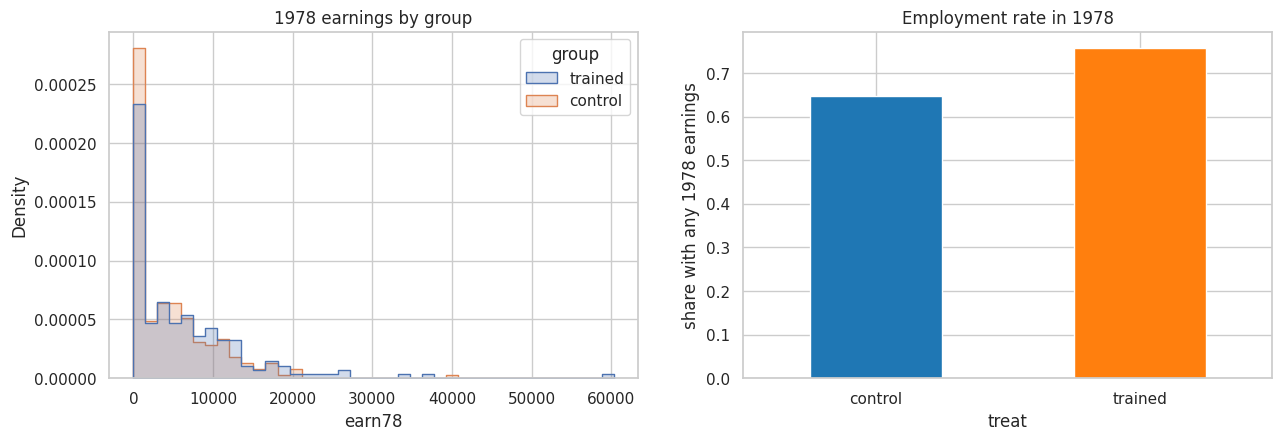

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(data=nsw.assign(group=nsw['treat'].map({1: 'trained', 0: 'control'})), x='earn78', hue='group',
             bins=40, element='step', stat='density', common_norm=False, ax=axes[0])
axes[0].set_title('1978 earnings by group')
(nsw.assign(employed=nsw['earn78'] > 0).groupby('treat')['employed'].mean()
    .rename({0: 'control', 1: 'trained'}).plot(kind='bar', ax=axes[1], color=['tab:blue', 'tab:orange'], rot=0))
axes[1].set_ylabel('share with any 1978 earnings'); axes[1].set_title('Employment rate in 1978');

### Did randomisation work? Checking balance
If assignment was random, the two groups should look alike **before** the programme. We measure this with the **standardised mean difference (SMD)**: the gap between the group means, in units of standard deviation. A common rule of thumb: **|SMD| < 0.1 means well balanced.**

In [4]:
covariates = ['age', 'educ', 'black', 'hispanic', 'married', 'nodegree', 'earn74', 'earn75']

def smd_table(df, treat='treat', cols=covariates, weights=None):
    # Standardised mean difference for each column (optionally with weights for the control group)
    t, c = df[df[treat] == 1], df[df[treat] == 0]
    w = np.ones(len(c)) if weights is None else np.asarray(weights)[df[treat].values == 0]
    out = {}
    for col in cols:
        mean_c = np.average(c[col], weights=w)
        var_c = np.average((c[col] - mean_c) ** 2, weights=w)
        out[col] = (t[col].mean() - mean_c) / np.sqrt((t[col].var() + var_c) / 2)
    return pd.Series(out, name='SMD')

smd_table(nsw).round(3)

age         0.107
educ        0.141
black       0.044
hispanic   -0.175
married     0.094
nodegree   -0.304
earn74     -0.002
earn75      0.084
Name: SMD, dtype: float64

**What to notice:** the differences are modest: half are under 0.1 and the largest (`nodegree`, about 0.3) is the kind of chance gap you expect when randomising a few hundred people. Nothing systematic separates the groups, so a **simple difference in means** is a fair estimate of the programme's effect. (Compare these SMDs with the ones in Part 5!)

In [5]:
treated, control = nsw[nsw['treat'] == 1], nsw[nsw['treat'] == 0]
effect = treated['earn78'].mean() - control['earn78'].mean()
se = np.sqrt(treated['earn78'].var() / len(treated) + control['earn78'].var() / len(control))
print(f'Trained: ${treated["earn78"].mean():,.0f} | control: ${control["earn78"].mean():,.0f}')
print(f'Experimental effect: ${effect:,.0f} (standard error ${se:,.0f}); '
      f'95% confidence interval ${effect - 1.96 * se:,.0f} to ${effect + 1.96 * se:,.0f}')
benchmark = effect          # the "true" answer we'll try to recover later without the experiment

Trained: $6,349 | control: $4,555
Experimental effect: $1,794 (standard error $671); 95% confidence interval $479 to $3,109


This **$1,794** is our **benchmark**: the answer from a randomised experiment, which we'll try to recover later without the experiment.

# Part 2: How a model learns: gradient descent
---
Fitting a model means choosing parameters (e.g. regression coefficients) that make a **loss function** as small as possible. This is **optimisation**.

- Sometimes calculus gives the answer directly (a **closed form**): set the derivative to zero and solve.
- Often it can't: then we use **gradient descent**, which repeatedly steps **downhill**:

1. Start somewhere.
2. Compute the **derivative** (the slope; with several parameters, the **gradient**).
3. Step in the opposite direction: $\theta_{new} = \theta - \alpha \times \text{slope}$, where $\alpha$ is the **learning rate** (step size).
4. Repeat until the steps become tiny.

### Food for thought: a function we can't solve by hand
$f(x) = -\ln(x) / (1 + x)$. Setting its derivative to zero gives an equation with no neat solution, so let gradient descent find the minimum.

After 300 steps: x = 3.5867, slope = -0.000075


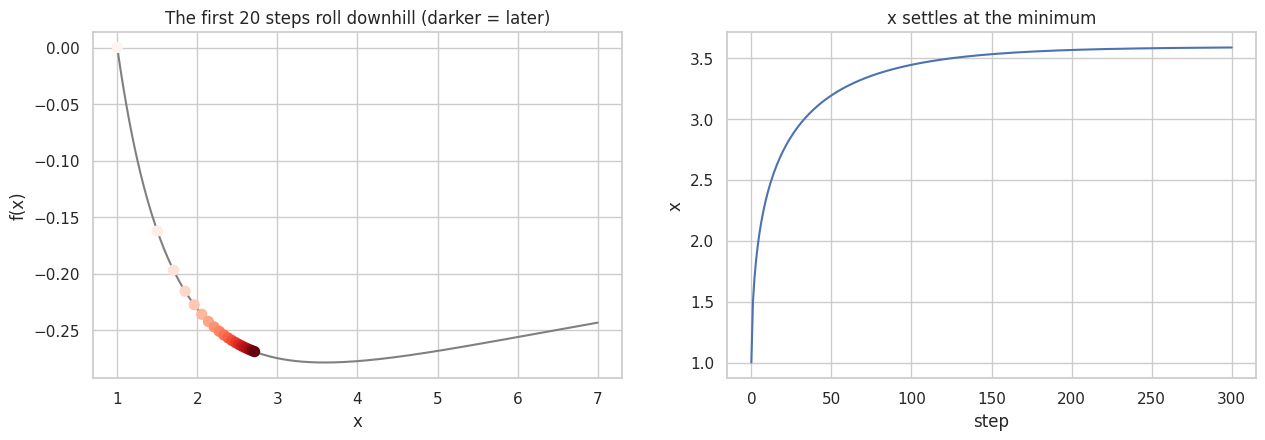

In [6]:
def f(x):
    return -np.log(x) / (1 + x)

def f_deriv(x):
    return -(1 + 1 / x - np.log(x)) / (1 + x) ** 2

x, alpha, path = 1.0, 1.0, [1.0]
for step in range(300):
    x = x - alpha * f_deriv(x)          # step downhill
    path.append(x)
print(f'After 300 steps: x = {x:.4f}, slope = {f_deriv(x):.6f}')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
xs = np.linspace(1, 7, 500)
axes[0].plot(xs, f(xs), color='grey')
axes[0].scatter(path[:20], f(np.array(path[:20])), c=range(20), cmap='Reds', s=50, zorder=3)
axes[0].set_title('The first 20 steps roll downhill (darker = later)'); axes[0].set_xlabel('x'); axes[0].set_ylabel('f(x)')
axes[1].plot(path); axes[1].set_xlabel('step'); axes[1].set_ylabel('x'); axes[1].set_title('x settles at the minimum');

**What to notice:** big steps at first (the slope is steep), tiny steps near the minimum (the slope is nearly zero). That's how gradient descent knows when to stop.

### Derivatives: which way is downhill?
The **sign** of the slope tells gradient descent which way to step:

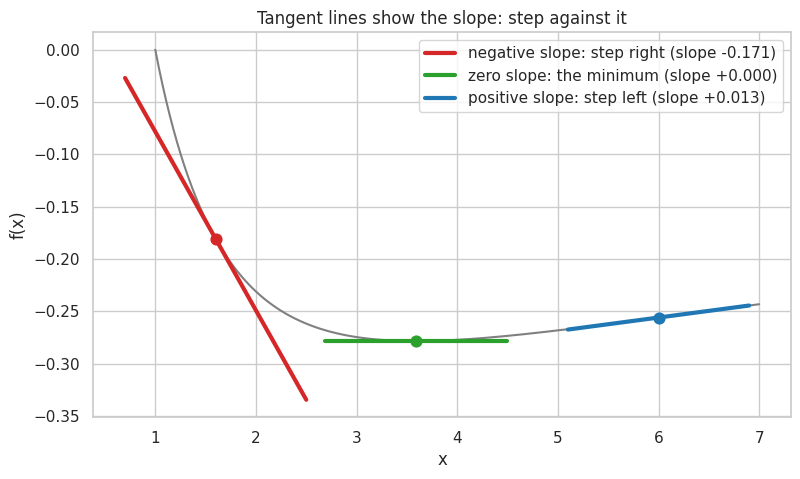

In [7]:
fig, ax = plt.subplots()
xs = np.linspace(1, 7, 500)
ax.plot(xs, f(xs), color='grey')
for x0, colour, label in [(1.6, 'tab:red', 'negative slope: step right'),
                          (3.5911, 'tab:green', 'zero slope: the minimum'),
                          (6.0, 'tab:blue', 'positive slope: step left')]:
    seg = np.linspace(x0 - 0.9, x0 + 0.9, 10)
    ax.plot(seg, f(x0) + f_deriv(x0) * (seg - x0), color=colour, lw=3, label=f'{label} (slope {round(f_deriv(x0), 3) + 0:+.3f})')
    ax.scatter([x0], [f(x0)], color=colour, s=60, zorder=3)
ax.set_xlabel('x'); ax.set_ylabel('f(x)'); ax.legend(); ax.set_title('Tangent lines show the slope: step against it');

### Our data: the loss for the earnings model
Model: $\text{earn78} = \beta_0 + \beta_1 \times \text{treat}$. The loss is the **mean squared error (MSE)**. Ordinary least squares *does* have a closed form, so we can check gradient descent against it: $\beta_0$ = the control mean, $\beta_1$ = the difference in means.

Closed form: beta0 = 4,554.8, beta1 = 1,794.3


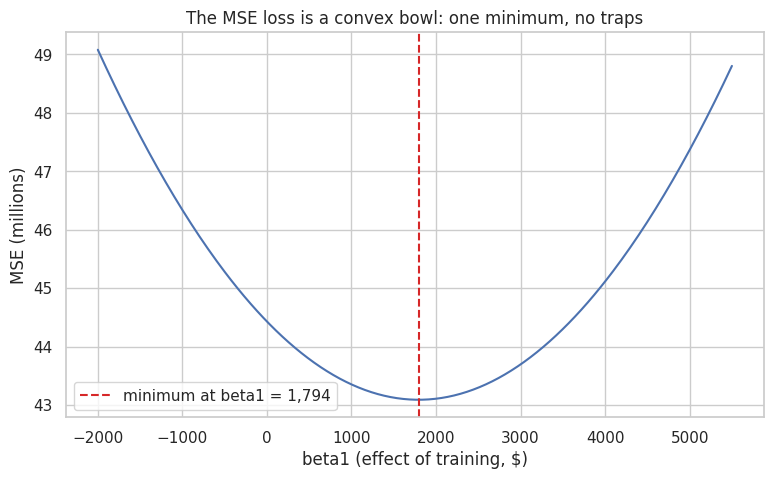

In [8]:
y = nsw['earn78'].values
X = np.c_[np.ones(len(nsw)), nsw['treat'].values]          # a column of 1s (intercept) and the treatment
closed_form = np.linalg.lstsq(X, y, rcond=None)[0]
print(f'Closed form: beta0 = {closed_form[0]:,.1f}, beta1 = {closed_form[1]:,.1f}')

b1_grid = np.linspace(-2000, 5500, 300)
mse = [np.mean((y - (closed_form[0] + b1 * X[:, 1])) ** 2) for b1 in b1_grid]
plt.plot(b1_grid, np.array(mse) / 1e6)
plt.axvline(closed_form[1], color='tab:red', ls='--', label=f'minimum at beta1 = {closed_form[1]:,.0f}')
plt.xlabel('beta1 (effect of training, $)'); plt.ylabel('MSE (millions)'); plt.legend()
plt.title('The MSE loss is a convex bowl: one minimum, no traps');

### Gradient descent for both coefficients
The gradient of the MSE is $-\frac{2}{n} X^T (y - X\beta)$. A reusable function:

In [9]:
def gradient_descent(X, y, alpha, n_steps=500):
    # Minimise MSE by gradient descent; returns the coefficients and the path (coefficients, loss) at each step
    beta = np.zeros(X.shape[1]); history = []
    for _ in range(n_steps):
        residuals = y - X @ beta
        history.append((beta.copy(), np.mean(residuals ** 2)))
        beta = beta - alpha * (-2 * X.T @ residuals / len(y))
        if not np.all(np.isfinite(beta)): break            # stop if it blows up
    return beta, history

beta_gd, history = gradient_descent(X, y, alpha=0.1)
print(f'Gradient descent: beta0 = {beta_gd[0]:,.1f}, beta1 = {beta_gd[1]:,.1f}   (closed form {closed_form.round(1)})')

Gradient descent: beta0 = 4,554.8, beta1 = 1,794.3   (closed form [4554.8 1794.3])


### Watching it learn: the path across the loss surface

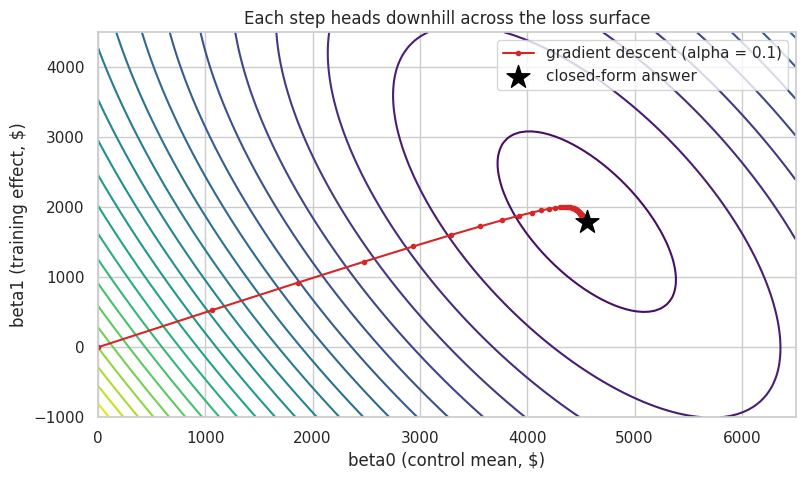

In [10]:
b0s, b1s = np.meshgrid(np.linspace(0, 6500, 120), np.linspace(-1000, 4500, 120))
loss = np.mean((y[None, None, :] - (b0s[..., None] + b1s[..., None] * X[:, 1])) ** 2, axis=2)
plt.contour(b0s, b1s, loss / 1e6, levels=30, cmap='viridis')
steps = np.array([b for b, _ in history[:60]])
plt.plot(steps[:, 0], steps[:, 1], 'o-', color='tab:red', ms=3, label='gradient descent (alpha = 0.1)')
plt.scatter(*closed_form, marker='*', s=300, color='black', label='closed-form answer', zorder=3)
plt.xlabel('beta0 (control mean, $)'); plt.ylabel('beta1 (training effect, $)'); plt.legend()
plt.title('Each step heads downhill across the loss surface');

### What can go wrong: the learning rate

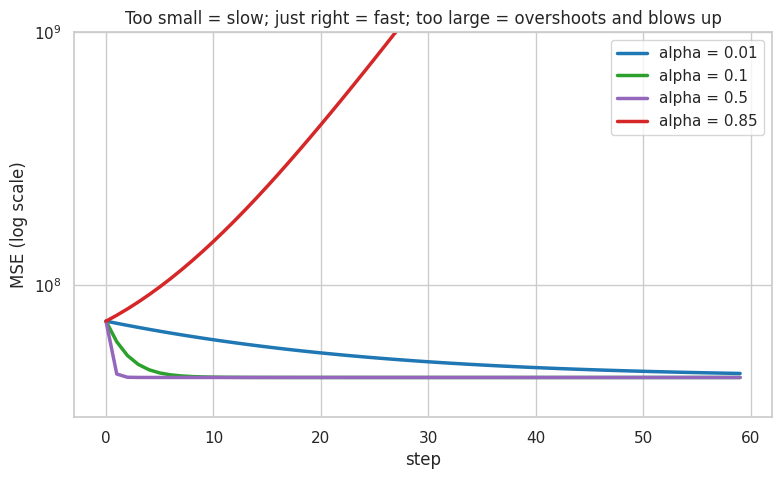

In [11]:
fig, ax = plt.subplots()
for alpha, colour in [(0.01, 'tab:blue'), (0.1, 'tab:green'), (0.5, 'tab:purple'), (0.85, 'tab:red')]:
    _, hist = gradient_descent(X, y, alpha, n_steps=60)
    ax.plot([l for _, l in hist], color=colour, lw=2.5, label=f'alpha = {alpha}')
ax.set_yscale('log'); ax.set_ylim(3e7, 1e9); ax.set_xlabel('step'); ax.set_ylabel('MSE (log scale)'); ax.legend()
ax.set_title('Too small = slow; just right = fast; too large = overshoots and blows up');

**What to notice:** α = 0.01 is still crawling; 0.1 and 0.5 converge quickly; **α = 0.85 overshoots** further each step and diverges. Other problems from the slides: **local minima** (avoided here because the MSE and log-loss are *convex*) and **flat curves**, which the next example shows.

### Local minima: why convexity matters
The MSE and log-loss are **convex** (one bowl). Many functions aren't. Here $g(x) = x^4 - 3x^2 + x$ has two dips, and where gradient descent ends up depends on **where it starts**:

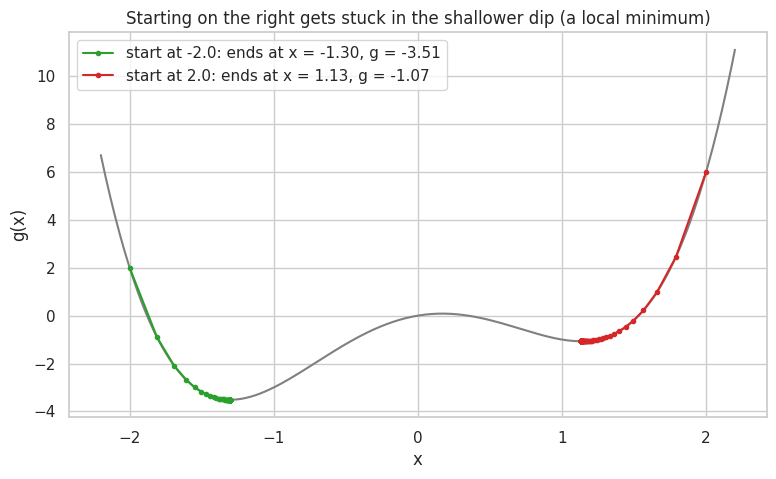

In [12]:
def g(x): return x ** 4 - 3 * x ** 2 + x
def g_deriv(x): return 4 * x ** 3 - 6 * x + 1

xs = np.linspace(-2.2, 2.2, 400)
plt.plot(xs, g(xs), color='grey')
for x0, colour in [(-2.0, 'tab:green'), (2.0, 'tab:red')]:
    x, trail = x0, [x0]
    for _ in range(200):
        x = x - 0.01 * g_deriv(x); trail.append(x)
    plt.plot(trail, g(np.array(trail)), 'o-', color=colour, ms=3, label=f'start at {x0}: ends at x = {x:.2f}, g = {g(x):.2f}')
plt.xlabel('x'); plt.ylabel('g(x)'); plt.legend()
plt.title('Starting on the right gets stuck in the shallower dip (a local minimum)');

**What to notice:** starting at +2 gets trapped in a **local** minimum; starting at −2 finds the deeper, **global** minimum. That's why convex losses are so convenient, and why neural networks (non-convex) are trained with tricks such as random restarts and momentum.

### Why scaling matters
Add 1975 earnings (in dollars, up to about $25,000) as a feature. Raw dollar values make the loss surface extremely stretched: any learning rate big enough to move the other coefficients makes the earnings coefficient blow up, so the largest *stable* rate barely moves at all.

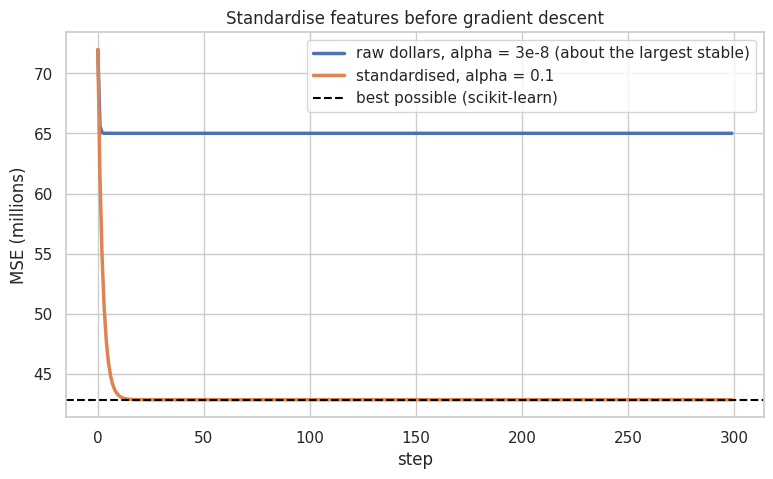

In [13]:
Xr = np.c_[np.ones(len(nsw)), nsw[['treat', 'earn75']].values]                         # raw units
Xs = np.c_[np.ones(len(nsw)), StandardScaler().fit_transform(nsw[['treat', 'earn75']])]  # standardised
ref = LinearRegression().fit(nsw[['treat', 'earn75']], y)
best_mse = np.mean((y - ref.predict(nsw[['treat', 'earn75']])) ** 2)

fig, ax = plt.subplots()
for X_, alpha, label in [(Xr, 3e-8, 'raw dollars, alpha = 3e-8 (about the largest stable)'), (Xs, 0.1, 'standardised, alpha = 0.1')]:
    _, hist = gradient_descent(X_, y, alpha, n_steps=300)
    ax.plot([l / 1e6 for _, l in hist], lw=2.5, label=label)
ax.axhline(best_mse / 1e6, color='black', ls='--', label='best possible (scikit-learn)')
ax.set_xlabel('step'); ax.set_ylabel('MSE (millions)'); ax.legend(); ax.set_title('Standardise features before gradient descent');

### Stochastic and mini-batch gradient descent
🔎 **Deep dive (optional in a 3-hour session)**

Instead of all 445 rows, each step uses a random **mini-batch** (here 32 rows). Each step is cheaper and noisier, but the loss still heads down. With millions of rows, this is the only practical option.

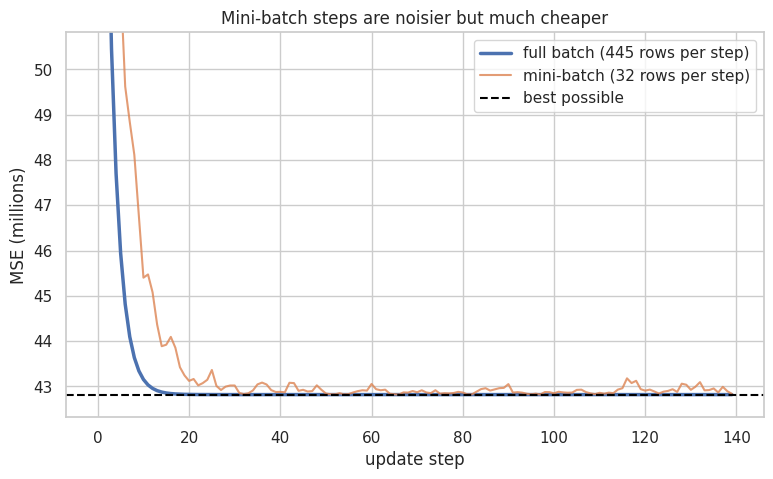

In [14]:
def minibatch_gd(X, y, alpha=0.05, batch_size=32, epochs=10, seed=0):
    rng_mb = np.random.default_rng(seed); beta = np.zeros(X.shape[1]); losses = []
    for epoch in range(epochs):
        order = rng_mb.permutation(len(y))
        for start in range(0, len(y), batch_size):
            rows = order[start:start + batch_size]
            residuals = y[rows] - X[rows] @ beta
            beta = beta - alpha * (-2 * X[rows].T @ residuals / len(rows))
            losses.append(np.mean((y - X @ beta) ** 2))             # full-data loss, for plotting
    return beta, losses

_, full_hist = gradient_descent(Xs, y, alpha=0.1, n_steps=140)
_, mb_losses = minibatch_gd(Xs, y)
plt.plot([l / 1e6 for _, l in full_hist], lw=2.5, label='full batch (445 rows per step)')
plt.plot(np.array(mb_losses) / 1e6, lw=1.5, alpha=0.8, label='mini-batch (32 rows per step)')
plt.axhline(best_mse / 1e6, color='black', ls='--', label='best possible')
plt.ylim(best_mse / 1e6 - 0.5, best_mse / 1e6 + 8)
plt.xlabel('update step'); plt.ylabel('MSE (millions)'); plt.legend(); plt.title('Mini-batch steps are noisier but much cheaper');

### Variations you'll meet
- **Stochastic / mini-batch gradient descent:** use a random handful of rows per step: noisier, but much cheaper for big data (the standard for neural networks).
- **Learning-rate schedules:** shrink α over time.
- **Fancier algorithms:** *momentum* and **Adam** (adaptive moment estimation) adapt the step for each parameter.
- **Second-order methods:** **Newton's method** also uses the *second* derivative (curvature) to take smarter steps:

In [15]:
def f_second(x, h=1e-5):
    return (f_deriv(x + h) - f_deriv(x - h)) / (2 * h)          # numerical second derivative

for name, update in [('gradient descent (alpha = 1)', lambda x: x - f_deriv(x)),
                     ("Newton's method", lambda x: x - f_deriv(x) / f_second(x))]:
    x, steps = 1.0, 0
    while abs(f_deriv(x)) > 1e-6:
        x, steps = update(x), steps + 1
    print(f'{name:30s} reaches x = {x:.4f} in {steps} steps')

gradient descent (alpha = 1)   reaches x = 3.5911 in 554 steps
Newton's method                reaches x = 3.5911 in 7 steps


**What to notice:** Newton's method needs a handful of steps instead of hundreds, at the cost of computing curvature (expensive with many parameters). scikit-learn's default solvers (e.g. L-BFGS, a "quasi-Newton" method) borrow this idea. Part 6 shows why that matters.

<details><summary><b>Check your understanding:</b> why do we standardise features before gradient descent?</summary>

Features on very different scales make the loss surface long and narrow, so one learning rate is too big in one direction and too small in another. Standardising makes the "bowl" rounder, so gradient descent can take sensible steps in every direction.
</details>

# Part 3: Bayesian modelling (1): the employment rate
---
**Bayesian recipe:** prior beliefs + data → **posterior** beliefs.

$$\underbrace{p(\theta \mid \text{data})}_{\text{posterior}} \;\propto\; \underbrace{p(\text{data} \mid \theta)}_{\text{likelihood}} \times \underbrace{p(\theta)}_{\text{prior}}$$

Here θ (theta) is the **employment rate**: the probability that a person has any earnings in 1978. For a probability, the natural prior is a **beta distribution**. Beta(1, 1) is flat: "every rate from 0% to 100% is equally plausible".

### Bayes' theorem with our own data
Bayes' theorem flips a conditional probability: $P(\text{trained} \mid \text{employed}) = \dfrac{P(\text{employed} \mid \text{trained})\, P(\text{trained})}{P(\text{employed})}$. Check it against a direct count:

In [16]:
employed_any = nsw['earn78'] > 0
p_trained = nsw['treat'].mean()
p_employed = employed_any.mean()
p_employed_given_trained = employed_any[nsw['treat'] == 1].mean()
bayes = p_employed_given_trained * p_trained / p_employed
print(f'P(employed | trained) = {p_employed_given_trained:.3f}, P(trained) = {p_trained:.3f}, P(employed) = {p_employed:.3f}')
print(f'Bayes: P(trained | employed) = {bayes:.3f}   |   direct count: {nsw.loc[employed_any, "treat"].mean():.3f}')

P(employed | trained) = 0.757, P(trained) = 0.416, P(employed) = 0.692
Bayes: P(trained | employed) = 0.455   |   direct count: 0.455


**The beta–binomial shortcut:** with a Beta(a, b) prior and *k* employed out of *n*, the posterior is **Beta(a + k, b + n − k)**: just add the successes and failures to the prior. (This is called a *conjugate* prior.)

employed / group size: {'trained': '140 / 185', 'control': '168 / 260'}


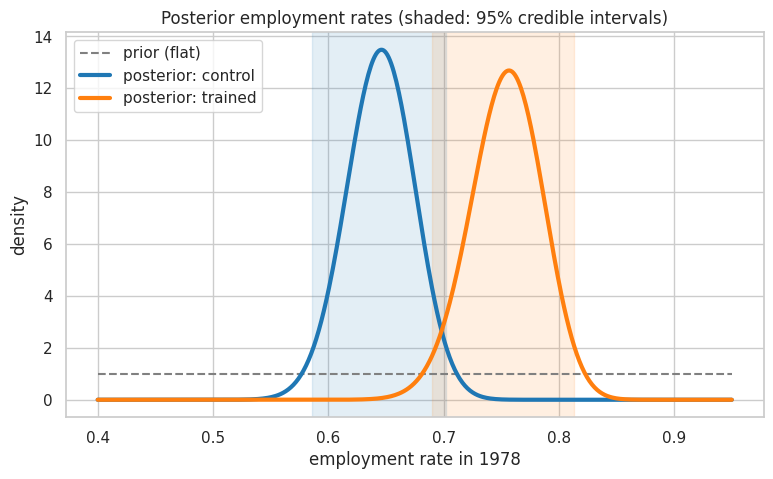

In [17]:
employed = {name: (g['earn78'] > 0).sum() for name, g in [('trained', treated), ('control', control)]}
sizes = {'trained': len(treated), 'control': len(control)}
print('employed / group size:', {k: f'{employed[k]} / {sizes[k]}' for k in employed})

prior_a, prior_b = 1, 1                                   # flat prior
posteriors = {k: stats.beta(prior_a + employed[k], prior_b + sizes[k] - employed[k]) for k in employed}

grid = np.linspace(0.4, 0.95, 500)
plt.plot(grid, stats.beta(prior_a, prior_b).pdf(grid), color='grey', ls='--', label='prior (flat)')
for k, colour in [('control', 'tab:blue'), ('trained', 'tab:orange')]:
    plt.plot(grid, posteriors[k].pdf(grid), color=colour, lw=3, label=f'posterior: {k}')
    lo, hi = posteriors[k].ppf([0.025, 0.975])
    plt.axvspan(lo, hi, color=colour, alpha=0.12)
plt.xlabel('employment rate in 1978'); plt.ylabel('density'); plt.legend()
plt.title('Posterior employment rates (shaded: 95% credible intervals)');

### Was the trained group really more likely to be employed?
With posteriors, we can answer this **directly**: draw many plausible rates from each posterior and count how often the trained rate is higher.

P(trained employment rate > control) = 0.994
Difference: mean 10.9%, 95% credible interval 2.4% to 19.2%


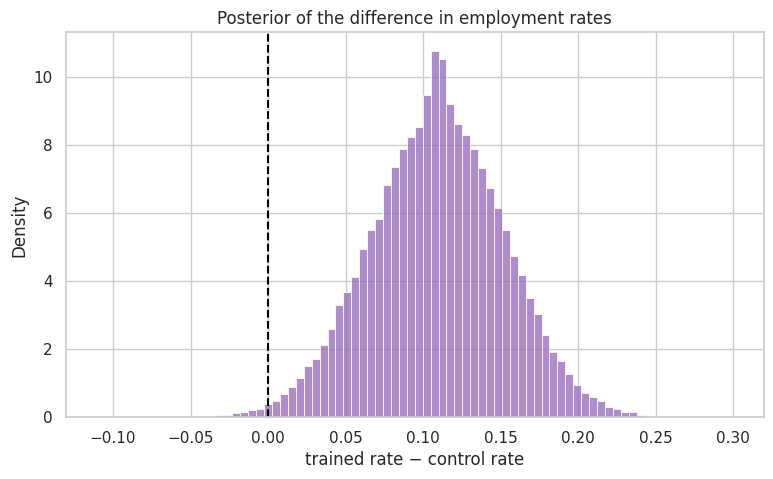

In [18]:
draws = {k: posteriors[k].rvs(100_000, random_state=1) for k in posteriors}
diff = draws['trained'] - draws['control']
print(f'P(trained employment rate > control) = {(diff > 0).mean():.3f}')
print(f'Difference: mean {diff.mean():.1%}, 95% credible interval {np.percentile(diff, 2.5):.1%} to {np.percentile(diff, 97.5):.1%}')
sns.histplot(diff, bins=80, stat='density', color='tab:purple')
plt.axvline(0, color='black', ls='--'); plt.xlabel('trained rate − control rate')
plt.title('Posterior of the difference in employment rates');

**What to notice:** "a **99% probability** that training raised the employment rate" is a statement managers understand immediately. A frequentist p-value can't be read that way.

### What does "95% confidence" actually mean?
🔎 **Deep dive (optional in a 3-hour session)**

A confidence interval is about the **method**. Simulate 100 experiments where we *know* the true effect is $1,000 (by resampling the control group and adding $1,000 to the "trained" group), build a 95% interval each time, and count how many capture the truth:

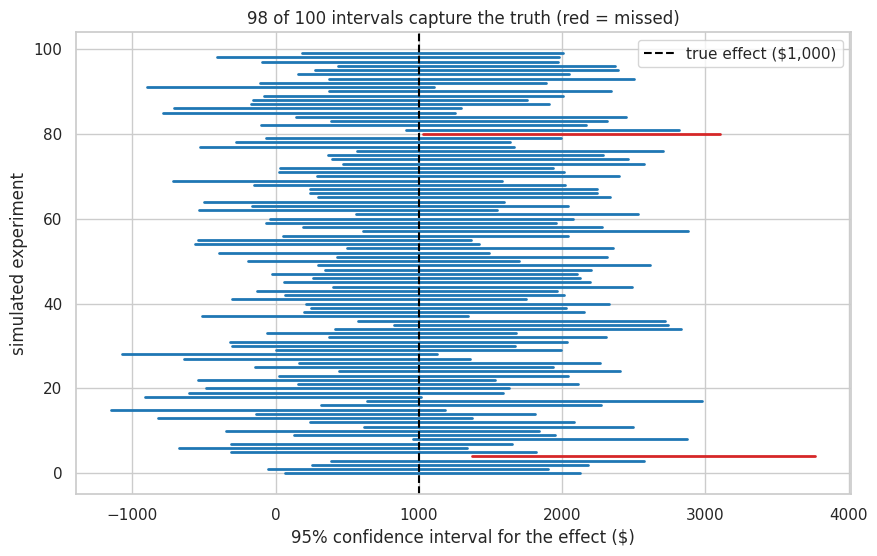

In [19]:
controls = nsw.loc[nsw['treat'] == 0, 'earn78'].values
sim_rng, true_effect, rows = np.random.default_rng(0), 1000, []
for i in range(100):
    a = sim_rng.choice(controls, 185) + true_effect          # simulated trained group
    b = sim_rng.choice(controls, 260)                         # simulated control group
    d = a.mean() - b.mean(); s_ = np.sqrt(a.var(ddof=1) / 185 + b.var(ddof=1) / 260)
    rows.append((d - 1.96 * s_, d + 1.96 * s_))
rows = np.array(rows); hit = (rows[:, 0] <= true_effect) & (rows[:, 1] >= true_effect)
plt.figure(figsize=(10, 6))
for i, (lo, hi) in enumerate(rows):
    plt.plot([lo, hi], [i, i], color='tab:blue' if hit[i] else 'tab:red', lw=2)
plt.axvline(true_effect, color='black', ls='--', label='true effect ($1,000)')
plt.xlabel('95% confidence interval for the effect ($)'); plt.ylabel('simulated experiment'); plt.legend()
plt.title(f'{hit.sum()} of 100 intervals capture the truth (red = missed)');

**What to notice:** about 95 in every 100 intervals catch the true value, but **any single interval either does or doesn't**. That's the frequentist meaning. A Bayesian credible interval instead makes a probability statement about *this* interval, given the prior and data.

<details><summary><b>Check your understanding:</b> what's the difference between a 95% <i>credible</i> interval and a 95% <i>confidence</i> interval?</summary>

A **credible interval** says "given the data and the prior, there's a 95% probability the true value is in this range". A **confidence interval** describes the *method*: 95% of intervals built this way would contain the true value. People often (wrongly) read confidence intervals as if they were credible intervals.
</details>

# Part 4: Bayesian modelling (2): the earnings effect, and why priors matter
---
For an average effect, a convenient model is the **normal–normal** one:
- **likelihood:** the data's estimate ($1,794) with its standard error ($671);
- **prior:** a normal distribution for the effect, with a mean and a spread that express what we believed beforehand.

The posterior mean is a **precision-weighted average** of the prior mean and the data (precision = 1 / variance): whichever is more certain gets more weight.

In [20]:
def posterior_normal(prior_mean, prior_sd, estimate, se):
    # Normal prior + normal likelihood -> normal posterior (mean, sd)
    precision = 1 / prior_sd ** 2 + 1 / se ** 2
    mean = (prior_mean / prior_sd ** 2 + estimate / se ** 2) / precision
    return mean, np.sqrt(1 / precision)

priors = {'flat (no prior opinion)': (0, 1e6), 'sceptical: "most programmes do little"': (0, 500),
          'optimistic: "about +$2,000"': (2000, 1000)}
rows = []
for name, (m0, s0) in priors.items():
    m, s = posterior_normal(m0, s0, benchmark, se)
    rows.append({'prior': name, 'posterior mean': m, '95% CrI low': m - 1.96 * s, '95% CrI high': m + 1.96 * s,
                 'P(effect > 0)': 1 - stats.norm.cdf(0, m, s), 'P(effect > $1,000)': 1 - stats.norm.cdf(1000, m, s)})
prior_table = pd.DataFrame(rows).set_index('prior')
prior_table.round(3)

,posterior mean,95% CrI low,95% CrI high,P(effect > 0),"P(effect > $1,000)"
prior,,,,,
flat (no prior opinion),1794.341,479.188,3109.494,0.996,0.882
"sceptical: ""most programmes do little""",640.620,-145.202,1426.442,0.945,0.185
"optimistic: ""about +$2,000""",1858.190,766.104,2950.276,1.000,0.938


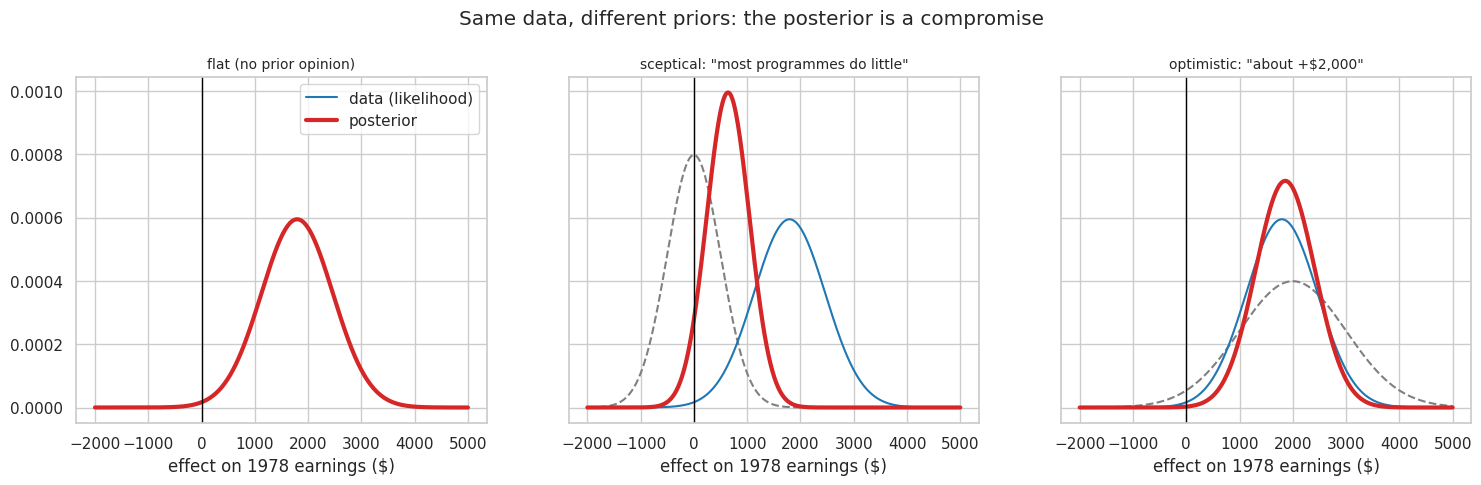

In [21]:
x = np.linspace(-2000, 5000, 600)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, (name, (m0, s0)) in zip(axes, priors.items()):
    m, s = posterior_normal(m0, s0, benchmark, se)
    if s0 < 1e5: ax.plot(x, stats.norm.pdf(x, m0, s0), color='grey', ls='--', label='prior')
    ax.plot(x, stats.norm.pdf(x, benchmark, se), color='tab:blue', label='data (likelihood)')
    ax.plot(x, stats.norm.pdf(x, m, s), color='tab:red', lw=3, label='posterior')
    ax.axvline(0, color='black', lw=1); ax.set_title(name, fontsize=10); ax.set_xlabel('effect on 1978 earnings ($)')
axes[0].legend(); plt.suptitle('Same data, different priors: the posterior is a compromise', y=1.03);

**What to notice:**
- With a **flat** prior, the posterior just follows the data.
- A **sceptical** prior pulls the estimate towards zero (to about $640) because a prior with a small spread is *very confident*. With only 445 people, the data can't fully overrule it.
- A **prior sensitivity analysis** like this is good practice: if the conclusion changes a lot with reasonable priors, say so.

### Updating as the data arrives
Bayesian updating is natural: today's posterior is tomorrow's prior. Watch the posterior sharpen as we add participants (starting from the sceptical prior):

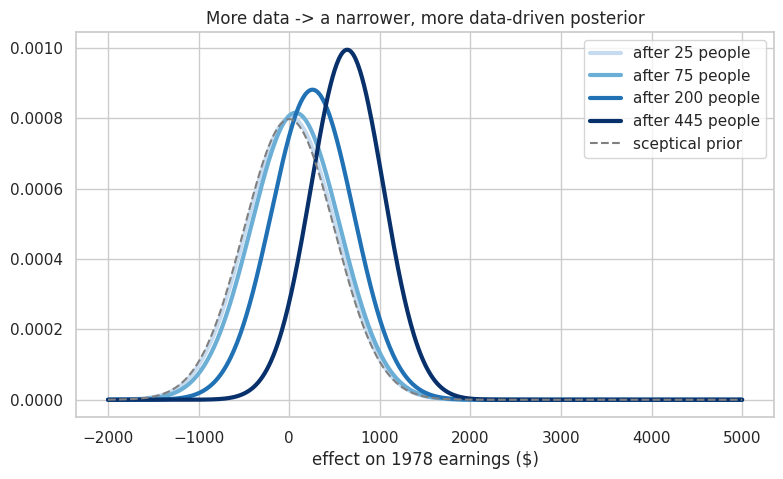

In [22]:
order = rng.permutation(len(nsw))
fig, ax = plt.subplots()
for n, colour in zip([25, 75, 200, 445], ['#c6dbef', '#6baed6', '#2171b5', '#08306b']):
    sub = nsw.iloc[order[:n]]
    t_, c_ = sub[sub['treat'] == 1]['earn78'], sub[sub['treat'] == 0]['earn78']
    est, s_ = t_.mean() - c_.mean(), np.sqrt(t_.var() / len(t_) + c_.var() / len(c_))
    m, s = posterior_normal(0, 500, est, s_)
    ax.plot(x, stats.norm.pdf(x, m, s), color=colour, lw=3, label=f'after {n} people')
ax.plot(x, stats.norm.pdf(x, 0, 500), color='grey', ls='--', label='sceptical prior')
ax.set_xlabel('effect on 1978 earnings ($)'); ax.legend(); ax.set_title('More data -> a narrower, more data-driven posterior');

<details><summary><b>Check your understanding:</b> how could you make the sceptical prior less influential?</summary>

Give it a **larger standard deviation** (be less confident), or collect **more data**: as the standard error shrinks, the data's precision outweighs the prior's.
</details>

### Gradient descent vs Bayes: one best value vs a whole distribution
Gradient descent can also work on a posterior: minimise the **negative log-posterior** (the data's loss **plus** a penalty from the prior). It finds the posterior's **peak**, the single most plausible value (the *MAP* estimate). A normal prior acts exactly like a **Ridge** penalty, pulling the estimate towards the prior mean.

In [23]:
b = 0.0
for step in range(50):
    gradient = (b - benchmark) / se ** 2 + (b - 0) / 500 ** 2          # data part + sceptical-prior part
    b = b - 1e5 * gradient
m_sceptical, _ = posterior_normal(0, 500, benchmark, se)
print(f'Gradient descent on the negative log-posterior: {b:,.1f}  |  posterior mean (formula): {m_sceptical:,.1f}')

Gradient descent on the negative log-posterior: 640.6  |  posterior mean (formula): 640.6


**What to notice:** gradient descent lands exactly on the posterior's peak (about $641). But it gives only **one number**; the Bayesian approach gives the **whole distribution**, so we can also say how sure we are.

### Seeing it: gradient descent climbing to the posterior's peak

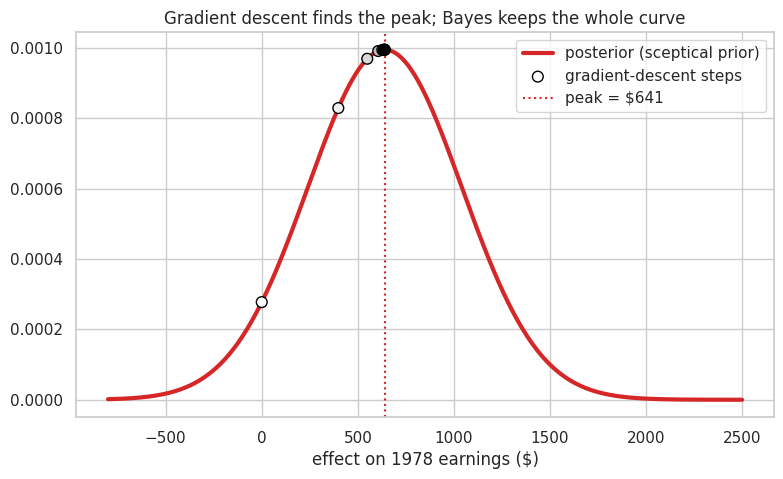

In [24]:
xs_b = np.linspace(-800, 2500, 400)
m_s, s_s = posterior_normal(0, 500, benchmark, se)
b, trail = 0.0, [0.0]
for step in range(8):
    b = b - 1e5 * ((b - benchmark) / se ** 2 + b / 500 ** 2); trail.append(b)
plt.plot(xs_b, stats.norm.pdf(xs_b, m_s, s_s), color='tab:red', lw=3, label='posterior (sceptical prior)')
plt.scatter(trail, stats.norm.pdf(trail, m_s, s_s), c=range(len(trail)), cmap='Greys', s=60, zorder=3, edgecolor='black', label='gradient-descent steps')
plt.axvline(m_s, color='tab:red', ls=':', label=f'peak = ${m_s:,.0f}')
plt.xlabel('effect on 1978 earnings ($)'); plt.legend(); plt.title('Gradient descent finds the peak; Bayes keeps the whole curve');

### A prior *is* a Ridge penalty
🔎 **Deep dive (optional in a 3-hour session)**

Fit Ridge regression of earnings on the treatment for several penalty strengths, and compare with the Bayesian posterior mean for a normal prior centred on 0. With the matching conversion **penalty = noise variance ÷ prior variance**, they are identical:

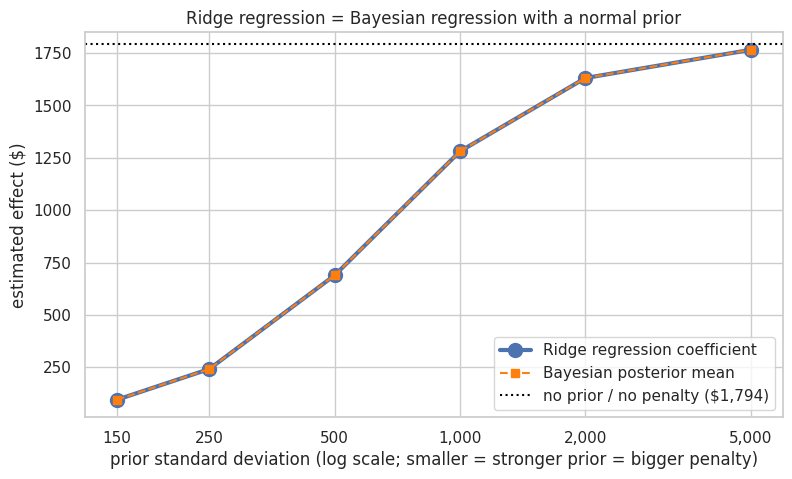

In [25]:
from sklearn.linear_model import Ridge
t_c = nsw['treat'].values - nsw['treat'].mean(); y_c = y - y.mean()
noise_var = np.var(y - LinearRegression().fit(nsw[['treat']], y).predict(nsw[['treat']]), ddof=2)
prior_sds = np.array([150, 250, 500, 1000, 2000, 5000])
ridge = [Ridge(alpha=noise_var / sd ** 2).fit(nsw[['treat']], y).coef_[0] for sd in prior_sds]
bayes = [(t_c @ y_c) / (t_c @ t_c + noise_var / sd ** 2) for sd in prior_sds]
plt.plot(prior_sds, ridge, 'o-', lw=3, ms=10, label='Ridge regression coefficient')
plt.plot(prior_sds, bayes, 's--', color='tab:orange', ms=6, label='Bayesian posterior mean')
plt.axhline(benchmark, color='black', ls=':', label='no prior / no penalty ($1,794)')
plt.xscale('log'); plt.xticks(prior_sds, [f'{v:,}' for v in prior_sds]); plt.minorticks_off()
plt.xlabel('prior standard deviation (log scale; smaller = stronger prior = bigger penalty)')
plt.ylabel('estimated effect ($)'); plt.legend(); plt.title('Ridge regression = Bayesian regression with a normal prior');

**What to notice:** a stronger prior (smaller standard deviation) is a bigger Ridge penalty, and both shrink the estimate towards 0 in exactly the same way. (The numbers differ slightly from the normal–normal model above, which allowed different spreads in the two groups.) A **Laplace** prior gives the **Lasso** in the same way.

---
☕ **Break**

---

# Part 5: Causal inference: when there's no experiment
---
Experiments are expensive or impossible for many questions. Usually we only have **observational** data: people who chose (or were chosen) to take part, compared with people who didn't.

LaLonde's test: keep the **185 trained people**, but replace the randomised control group with **15,992 people from a national survey** (who were not in the programme). Can we still get close to the true effect of **$1,794**?

In [26]:
survey = pd.read_csv('../data/cps_survey.csv')
obs = pd.concat([treated, survey], ignore_index=True)        # trained people + survey "controls"
print(obs.shape, '| trained:', obs['treat'].sum())

naive = obs[obs['treat'] == 1]['earn78'].mean() - obs[obs['treat'] == 0]['earn78'].mean()
print(f'Naive comparison: ${naive:,.0f}   vs   experimental benchmark: ${benchmark:,.0f}')

(16177, 10) | trained: 185
Naive comparison: $-8,498   vs   experimental benchmark: $1,794


**The naive answer says training *cut* earnings by about $8,500, the wrong sign entirely!** Why? Look at *who* the two groups are:

In [27]:
compare = obs.groupby('treat')[covariates].mean().T.rename(columns={0: 'survey', 1: 'trained'})
compare['SMD'] = smd_table(obs)
compare.round(2)

treat,survey,trained,SMD
age,33.23,25.82,-0.80
educ,12.03,10.35,-0.68
black,0.07,0.84,2.43
hispanic,0.07,0.06,-0.05
married,0.71,0.19,-1.23
nodegree,0.30,0.71,0.90
earn74,14016.80,2095.57,-1.57
earn75,13650.80,1532.06,-1.75


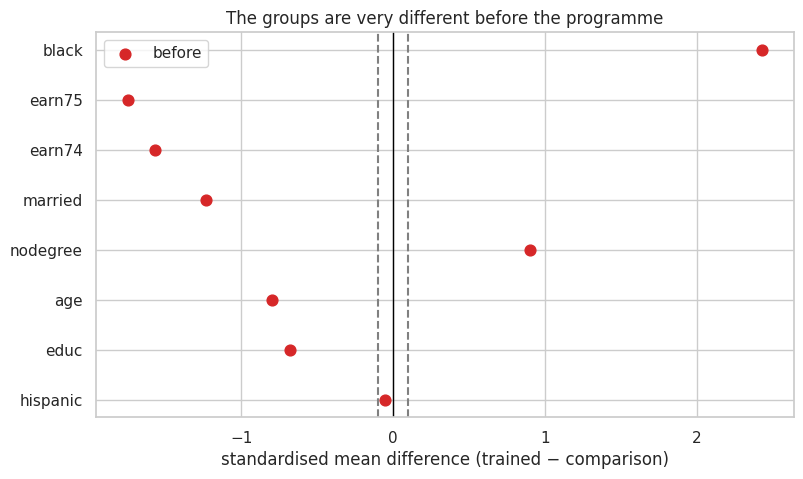

In [28]:
def love_plot(smd_before, smd_after=None, title=''):
    order = smd_before.abs().sort_values().index
    plt.scatter(smd_before[order], order, color='tab:red', s=60, label='before')
    if smd_after is not None:
        plt.scatter(smd_after[order], order, color='tab:green', s=60, label='after')
    for v in (-0.1, 0.1): plt.axvline(v, color='grey', ls='--')
    plt.axvline(0, color='black', lw=1); plt.xlabel('standardised mean difference (trained − comparison)')
    plt.title(title); plt.legend()

love_plot(smd_table(obs), title='The groups are very different before the programme')

**What to notice:** the trained group is younger, less educated, much more likely to be Black and unmarried, and earned **far less** in 1974–75 (SMDs of 1.5–2.4). These background differences, called **confounders**, affect *both* who got training *and* later earnings. The naive comparison mixes the programme's effect with these pre-existing gaps.

### A picture of confounding

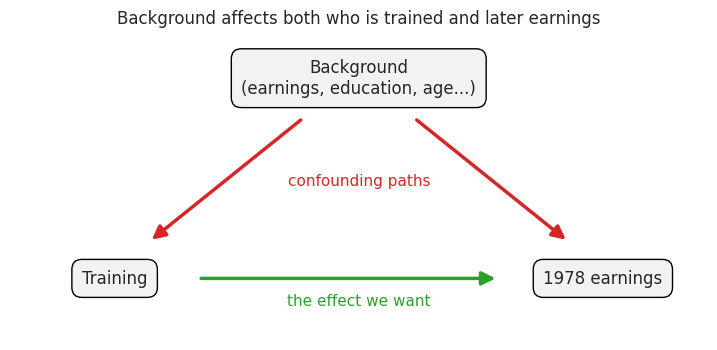

In [29]:
fig, ax = plt.subplots(figsize=(9, 4)); ax.axis('off')
boxes = {'Background\n(earnings, education, age...)': (0.5, 0.85), 'Training': (0.15, 0.2), '1978 earnings': (0.85, 0.2)}
for text, (bx, by) in boxes.items():
    ax.text(bx, by, text, ha='center', va='center', fontsize=12, bbox=dict(boxstyle='round,pad=0.6', fc='#f2f2f2', ec='black'))
arrow = dict(arrowstyle='-|>', lw=2.5, mutation_scale=20)
ax.annotate('', xy=(0.2, 0.32), xytext=(0.42, 0.72), arrowprops={**arrow, 'color': 'tab:red'})
ax.annotate('', xy=(0.8, 0.32), xytext=(0.58, 0.72), arrowprops={**arrow, 'color': 'tab:red'})
ax.annotate('', xy=(0.7, 0.2), xytext=(0.27, 0.2), arrowprops={**arrow, 'color': 'tab:green'})
ax.text(0.5, 0.11, 'the effect we want', color='tab:green', ha='center', fontsize=11)
ax.text(0.5, 0.5, 'confounding paths', color='tab:red', ha='center', fontsize=11)
ax.set_title('Background affects both who is trained and later earnings');

### Randomised vs observational, side by side

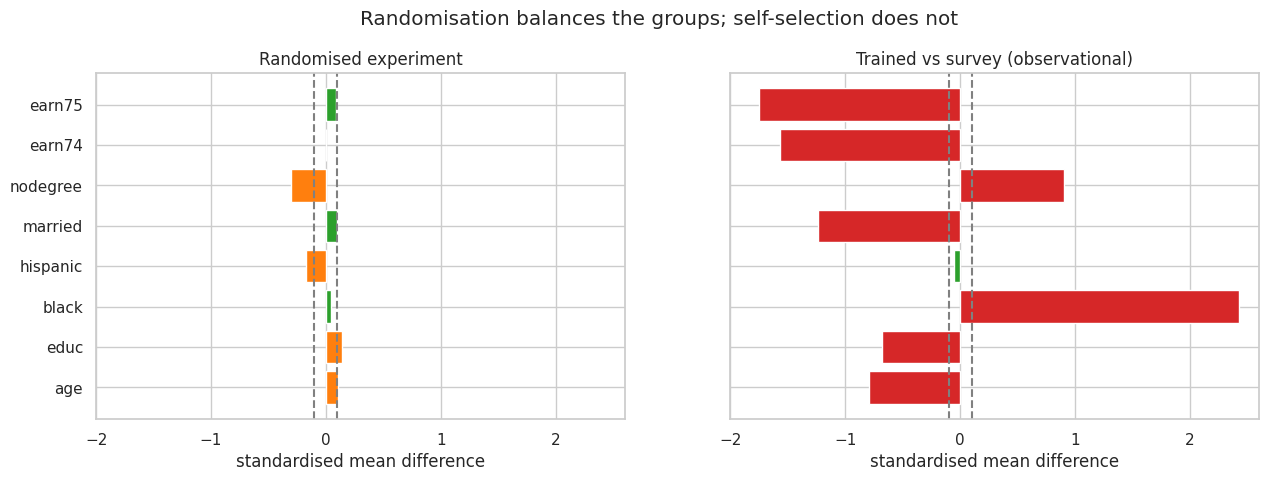

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (name, data) in zip(axes, [('Randomised experiment', nsw), ('Trained vs survey (observational)', obs)]):
    smd_vals = smd_table(data).reindex(covariates)
    ax.barh(covariates, smd_vals, color=['tab:green' if abs(v) < 0.1 else 'tab:orange' if abs(v) < 0.5 else 'tab:red' for v in smd_vals])
    for v in (-0.1, 0.1): ax.axvline(v, color='grey', ls='--')
    ax.set_xlim(-2.0, 2.6); ax.set_title(name); ax.set_xlabel('standardised mean difference')
plt.suptitle('Randomisation balances the groups; self-selection does not', y=1.02);

### Potential outcomes: the language of causal inference
For each person *i* imagine two **potential outcomes**:
- $Y_i(1)$: earnings **if trained**;
- $Y_i(0)$: earnings **if not trained**.

The causal effect for that person is $Y_i(1) - Y_i(0)$. **The fundamental problem of causal inference:** we only ever see **one** of the two. The other is **missing**. (This is Rubin's key insight: causal inference *is* a missing-data problem.)

| person | trained? | $Y(1)$ | $Y(0)$ | effect |
|---|---|---|---|---|
| A | yes | 9,930 | **?** | ? |
| B | no | **?** | 4,200 | ? |

**Randomisation** makes the "?" values fill in fairly on average: the control group's outcomes are a good stand-in for what the trained group *would* have earned. Without randomisation, we must make the groups comparable ourselves, using the confounders.

We'll estimate the **ATT** (average treatment effect on the treated): the average effect for the people who were actually trained, which is what the experiment measured.

## Fix 1: regression adjustment
Put the treatment indicator **and** the confounders into a linear regression: the treatment coefficient is the effect "holding the confounders constant".

In [31]:
obs['unemployed74'] = (obs['earn74'] == 0).astype(int)        # zero earnings are informative
obs['unemployed75'] = (obs['earn75'] == 0).astype(int)
adjust = covariates + ['unemployed74', 'unemployed75']
reg = LinearRegression().fit(obs[['treat'] + adjust], obs['earn78'])
reg_effect = reg.coef_[0]
print(f'Regression-adjusted effect: ${reg_effect:,.0f}   (benchmark ${benchmark:,.0f})')

Regression-adjusted effect: $1,066   (benchmark $1,794)


Much closer, but regression assumes straight-line relationships and leans on survey people who are nothing like the trainees (e.g. high earners). Next, an approach that compares like with like.

# Part 6: Propensity scores, matching and weighting
---
The **propensity score** is each person's probability of being in the trained group, **given their background**: $e(x) = P(\text{treat} = 1 \mid x)$. We estimate it with **logistic regression**.

Rosenbaum and Rubin (1983) showed that people with the **same propensity score** have, on average, the same mix of background characteristics, so comparing trained and untrained people with similar scores is like a mini-experiment.

In [32]:
features = obs[adjust].copy()
for col in ['age', 'educ', 'earn74', 'earn75']:
    features[col + '_sq'] = obs[col] ** 2                     # allow curved relationships
Zf = StandardScaler().fit_transform(features)
ps_model = LogisticRegression(C=1e6, max_iter=5000).fit(Zf, obs['treat'])
obs['ps'] = ps_model.predict_proba(Zf)[:, 1]
obs.groupby('treat')['ps'].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
treat,,,,,,,,
0,15992.0,0.007,0.043,0.0,0.000,0.000,0.001,0.890
1,185.0,0.401,0.287,0.0,0.121,0.433,0.616,0.893


### Under the hood: fitting the propensity model by gradient descent
Logistic regression minimises the **log-loss**. Let's fit it with plain gradient descent and compare with scikit-learn, which uses **L-BFGS** (a quasi-Newton method).

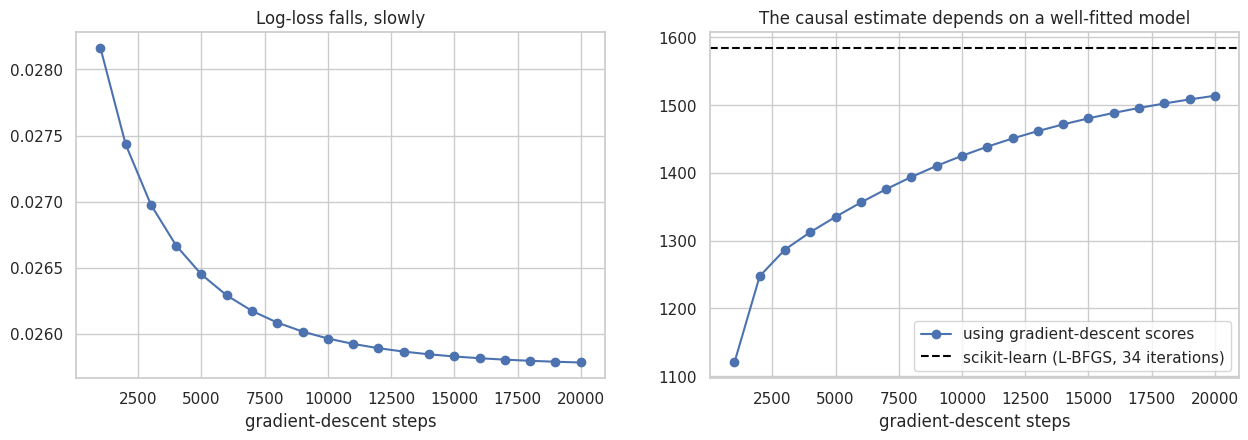

In [33]:
Zb = np.c_[np.ones(len(Zf)), Zf]                                    # standardised features + intercept
T = obs['treat'].values
y_obs = obs['earn78'].values
def ipw_from(p):
    return y_obs[T == 1].mean() - np.average(y_obs[T == 0], weights=(p / (1 - p))[T == 0])

w, record = np.zeros(Zb.shape[1]), []
for step in range(1, 20001):
    p = 1 / (1 + np.exp(-np.clip(Zb @ w, -35, 35)))
    w = w - 4.0 * Zb.T @ (p - T) / len(T)                          # gradient of the log-loss
    if step % 1000 == 0:
        log_loss = -np.mean(T * np.log(p + 1e-12) + (1 - T) * np.log(1 - p + 1e-12))
        record.append((step, log_loss, ipw_from(p)))
record = pd.DataFrame(record, columns=['step', 'log-loss', 'IPW estimate'])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(record['step'], record['log-loss'], marker='o'); axes[0].set_title('Log-loss falls, slowly')
axes[1].plot(record['step'], record['IPW estimate'], marker='o', label='using gradient-descent scores')
axes[1].axhline(ipw_from(obs['ps'].values), color='black', ls='--', label=f'scikit-learn (L-BFGS, {ps_model.n_iter_[0]} iterations)')
axes[1].set_title('The causal estimate depends on a well-fitted model'); axes[1].legend()
for ax in axes: ax.set_xlabel('gradient-descent steps')

**What to notice:** plain gradient descent needs **tens of thousands** of steps and still hasn't quite matched scikit-learn, whose quasi-Newton solver finishes in a few dozen. A propensity model that hasn't converged gives a different causal estimate, so always check that your model has converged (scikit-learn warns you if it hasn't).

### Overlap: are there comparable people?
Effects can only be estimated where both groups have people with similar scores (**overlap**, or *common support*).

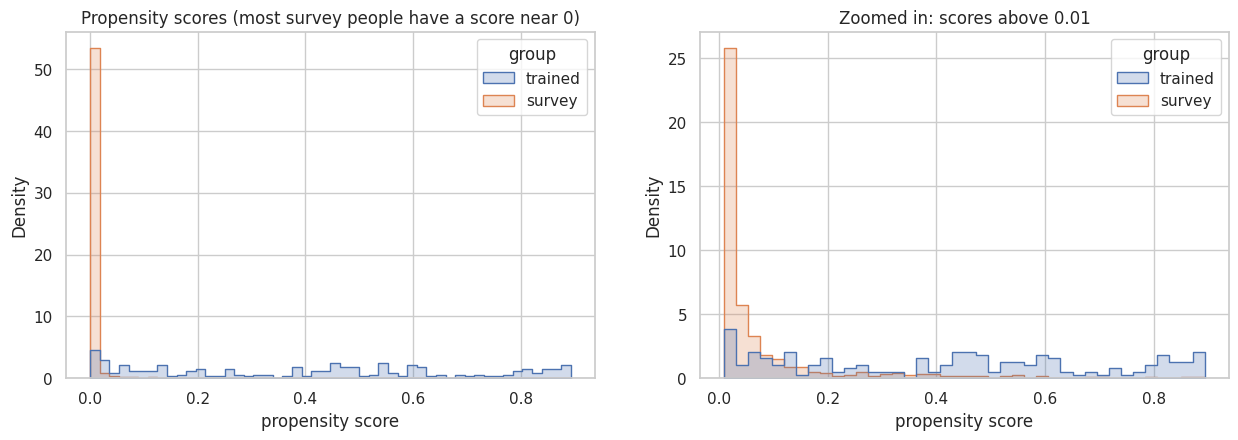

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
labelled = obs.assign(group=obs['treat'].map({1: 'trained', 0: 'survey'}))
sns.histplot(data=labelled, x='ps', hue='group', bins=50, stat='density', common_norm=False, element='step', ax=axes[0])
axes[0].set_title('Propensity scores (most survey people have a score near 0)')
sns.histplot(data=labelled[labelled['ps'] > 0.01], x='ps', hue='group', bins=40, stat='density', common_norm=False, element='step', ax=axes[1])
axes[1].set_title('Zoomed in: scores above 0.01'); axes[1].set_xlabel('propensity score'); axes[0].set_xlabel('propensity score');

**What to notice:** almost all survey people have a near-zero score: they look nothing like the trainees. But several hundred have scores comparable to the trained group: those are the people we need.

## Fix 2: propensity-score matching
For each trained person, find the survey person with the **closest propensity score** (1-to-1 nearest neighbour, with replacement). The matched person's earnings fill in the missing $Y(0)$.

In [35]:
tr, co = obs[obs['treat'] == 1], obs[obs['treat'] == 0]
nn = NearestNeighbors(n_neighbors=1).fit(co[['ps']])
_, idx = nn.kneighbors(tr[['ps']])
matched = co.iloc[idx[:, 0]]
match_effect = (tr['earn78'].values - matched['earn78'].values).mean()
print(f'Matching effect: ${match_effect:,.0f}   (benchmark ${benchmark:,.0f}) | distinct survey people used: {matched.index.nunique()}')

Matching effect: $1,642   (benchmark $1,794) | distinct survey people used: 111


The missing-data view in action: each trained person's unobserved $Y(0)$ is **imputed** by their match:

In [36]:
pd.DataFrame({'trained person': tr.index[:5], 'Y(1) observed': tr['earn78'].values[:5].round(0),
              'Y(0) imputed from match': matched['earn78'].values[:5].round(0),
              'their propensity score': tr['ps'].values[:5].round(3),
              "match's score": matched['ps'].values[:5].round(3)})

,trained person,Y(1) observed,Y(0) imputed from match,their propensity score,match's score
0,0,9930.0,0.0,0.493,0.489
1,1,3596.0,9565.0,0.281,0.279
2,2,24909.0,1899.0,0.714,0.714
3,3,7506.0,13883.0,0.848,0.851
4,4,290.0,0.0,0.893,0.890


## Fix 3: inverse-probability weighting (IPW)
Instead of picking matches, **re-weight** the survey people so they look like the trained group: a survey person with score *e* gets weight *e* / (1 − *e*). People who look like trainees count a lot; people who look nothing like them count almost zero.

In [37]:
obs['weight'] = np.where(obs['treat'] == 1, 1, obs['ps'] / (1 - obs['ps']))
w_c = obs.loc[obs['treat'] == 0, 'weight']
ipw_effect = obs.loc[obs['treat'] == 1, 'earn78'].mean() - np.average(obs.loc[obs['treat'] == 0, 'earn78'], weights=w_c)
ess = w_c.sum() ** 2 / (w_c ** 2).sum()                          # Kish effective sample size
print(f'IPW effect: ${ipw_effect:,.0f}   (benchmark ${benchmark:,.0f})')
print(f'The 15,992 weighted survey people are worth about {ess:,.0f} "effective" people')

IPW effect: $1,585   (benchmark $1,794)
The 15,992 weighted survey people are worth about 107 "effective" people


### Did it work? Check balance after weighting
**Always** check balance after matching or weighting: it's the evidence that the comparison is now fair.

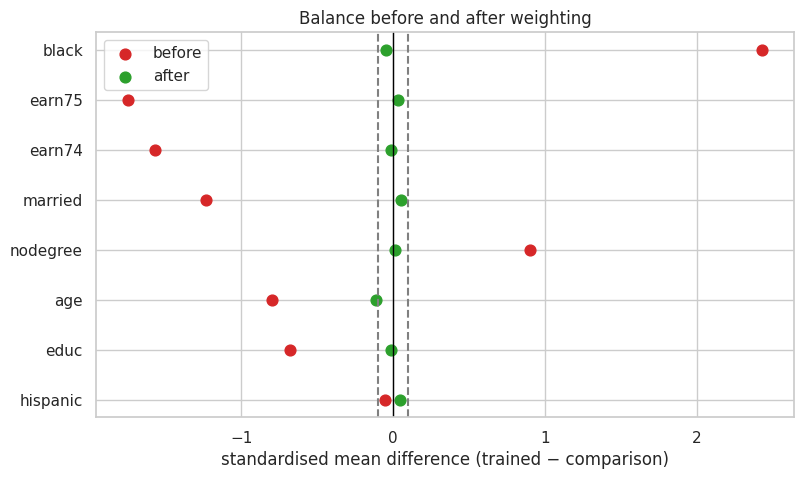

In [38]:
love_plot(smd_table(obs), smd_table(obs, weights=obs['weight']), title='Balance before and after weighting')

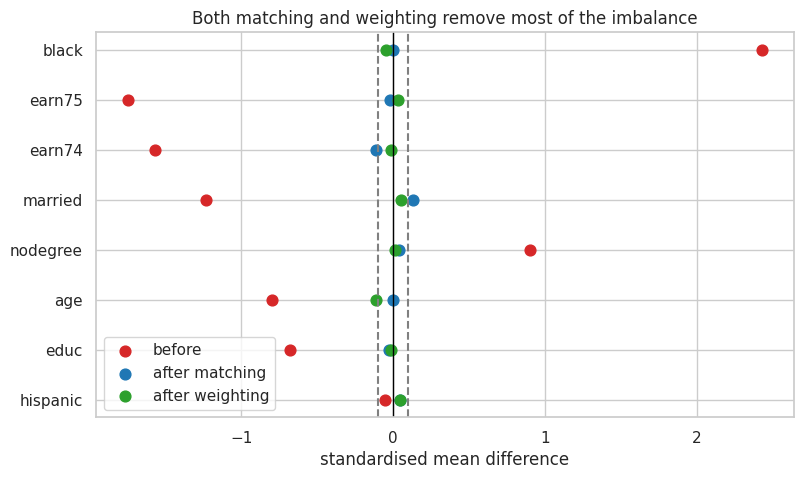

In [39]:
before_smd = smd_table(obs)
matched_df = pd.concat([tr, matched.assign(treat=0)])                 # trained people + their matches
after_match = smd_table(matched_df)
after_weight = smd_table(obs, weights=obs['weight'])
order_ = before_smd.abs().sort_values().index
for series, colour, label in [(before_smd, 'tab:red', 'before'), (after_match, 'tab:blue', 'after matching'),
                              (after_weight, 'tab:green', 'after weighting')]:
    plt.scatter(series[order_], order_, color=colour, s=60, label=label)
for v in (-0.1, 0.1): plt.axvline(v, color='grey', ls='--')
plt.axvline(0, color='black', lw=1); plt.xlabel('standardised mean difference'); plt.legend()
plt.title('Both matching and weighting remove most of the imbalance');

### The scorecard

,estimate ($),error vs benchmark ($)
Naive comparison,-8498.0,-10292.0
Regression adjustment,1066.0,-728.0
Propensity-score matching,1642.0,-152.0
Inverse-probability weighting,1585.0,-209.0


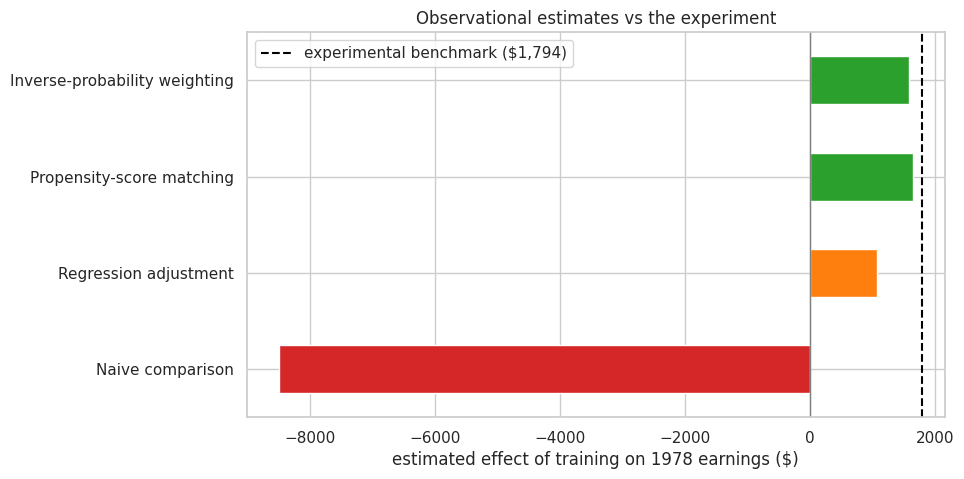

In [40]:
results = pd.Series({'Naive comparison': naive, 'Regression adjustment': reg_effect,
                     'Propensity-score matching': match_effect, 'Inverse-probability weighting': ipw_effect})
scorecard = pd.DataFrame({'estimate ($)': results, 'error vs benchmark ($)': results - benchmark})
display(scorecard.round(0))
ax = results.plot(kind='barh', color=['tab:red', 'tab:orange', 'tab:green', 'tab:green'])
ax.axvline(benchmark, color='black', ls='--', label=f'experimental benchmark (${benchmark:,.0f})')
ax.axvline(0, color='grey', lw=1); ax.set_xlabel('estimated effect of training on 1978 earnings ($)'); ax.legend()
plt.title('Observational estimates vs the experiment');

**What to notice:** the naive comparison is badly wrong; adjusting for confounders, and especially comparing like with like (matching, weighting), brings us close to the experimental answer, **without using the experiment's control group at all**.

**Assumptions these methods rely on** (state them whenever you use them):
1. **No unmeasured confounding:** we've measured everything that affects both treatment and outcome (here, pre-programme earnings are crucial).
2. **Overlap:** comparable people exist in both groups.
3. **No interference:** one person's training doesn't change another's earnings.

### Sensitivity check: what if a confounder were missing?
We can't test "no unmeasured confounding" directly, but we can see how much the answer depends on each confounder by **leaving it out** of the propensity model:

all confounders              1585.0
without race                  919.0
without education            1226.0
without previous earnings   -3499.0
dtype: float64

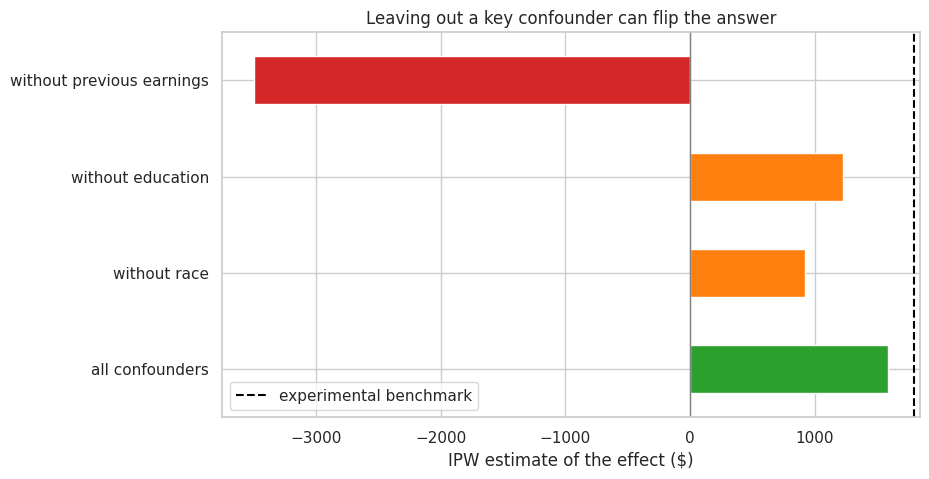

In [41]:
def ipw_without(drop):
    cols = [c for c in features.columns if not any(c.startswith(d) for d in drop)]
    Z_ = StandardScaler().fit_transform(features[cols])
    p = LogisticRegression(C=1e6, max_iter=5000).fit(Z_, obs['treat']).predict_proba(Z_)[:, 1]
    w_ = p / (1 - p)
    return obs.loc[obs['treat'] == 1, 'earn78'].mean() - np.average(obs.loc[obs['treat'] == 0, 'earn78'], weights=w_[obs['treat'].values == 0])

sens = pd.Series({'all confounders': ipw_effect,
                  'without race': ipw_without(['black', 'hispanic']),
                  'without education': ipw_without(['educ', 'nodegree']),
                  'without previous earnings': ipw_without(['earn74', 'earn75', 'unemployed74', 'unemployed75'])})
ax = sens.plot(kind='barh', color=['tab:green', 'tab:orange', 'tab:orange', 'tab:red'])
ax.axvline(benchmark, color='black', ls='--', label='experimental benchmark'); ax.axvline(0, color='grey', lw=1)
ax.set_xlabel('IPW estimate of the effect ($)'); ax.legend(); ax.set_title('Leaving out a key confounder can flip the answer')
sens.round(0)

<details><summary><b>Check your understanding:</b> which single variable do you think matters most for fixing the bias here, and why?</summary>

**Earlier earnings** (`earn74`, `earn75` and the unemployment flags). They strongly predict both who joined a programme for disadvantaged workers *and* later earnings. The sensitivity chart above shows it: without them, the estimate flips to a large *negative* effect.
</details>

# Part 7: Bringing it together: a Bayesian posterior for a causal effect
---
Rubin's view links the two halves: **causal inference = imputing missing potential outcomes, with honest uncertainty.** A simple way to get a posterior for any estimate is Rubin's **Bayesian bootstrap** (1981): give every person a random weight (from a Dirichlet distribution), recompute the estimate, and repeat thousands of times. The spread of the results is a posterior distribution for the effect.

(Simplification for teaching: we keep the propensity scores fixed rather than re-estimating them in every draw.)

In [42]:
def bayesian_bootstrap(estimator, n_rows, draws=2000, seed=0):
    # Posterior draws of an estimate: re-weight the rows with Dirichlet(1, ..., 1) weights each time
    g = np.random.default_rng(seed)
    return np.array([estimator(g.dirichlet(np.ones(n_rows))) for _ in range(draws)])

def diff_in_means(df):
    y, t = df['earn78'].values, df['treat'].values == 1
    return lambda w: np.average(y[t], weights=w[t]) - np.average(y[~t], weights=w[~t])

def ipw_att(df):
    y, t, base = df['earn78'].values, df['treat'].values == 1, df['weight'].values
    return lambda w: np.average(y[t], weights=w[t]) - np.average(y[~t], weights=(w * base)[~t])

post = {'Experiment (randomised)': bayesian_bootstrap(diff_in_means(nsw), len(nsw)),
        'Observational: naive': bayesian_bootstrap(diff_in_means(obs), len(obs), draws=1000),
        'Observational: IPW': bayesian_bootstrap(ipw_att(obs), len(obs), draws=1000)}
summary = pd.DataFrame({name: {'posterior mean': d.mean(), '95% CrI low': np.percentile(d, 2.5),
                               '95% CrI high': np.percentile(d, 97.5), 'P(effect > 0)': (d > 0).mean()}
                        for name, d in post.items()}).T
summary.round(3)

,posterior mean,95% CrI low,95% CrI high,P(effect > 0)
Experiment (randomised),1799.308,548.794,3177.461,0.998
Observational: naive,-8487.336,-9540.071,-7320.659,0.000
Observational: IPW,1588.581,159.892,3060.413,0.987


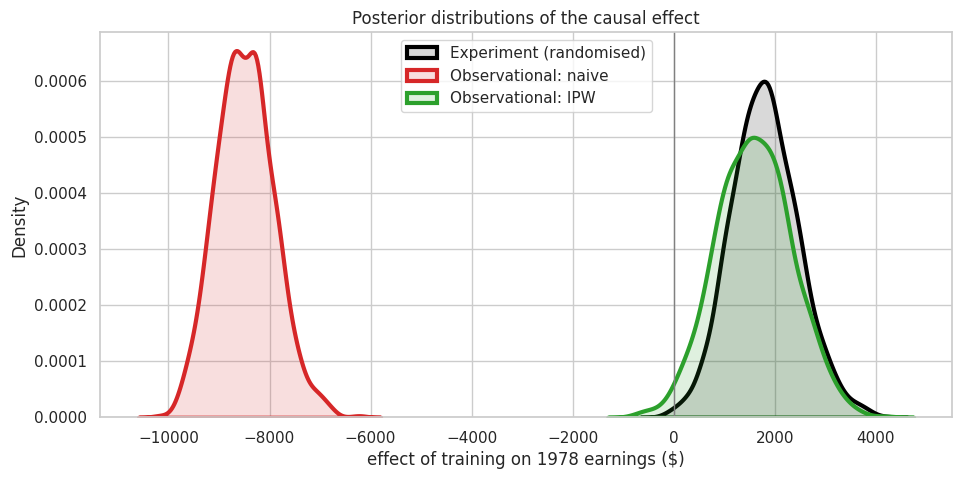

In [43]:
fig, ax = plt.subplots(figsize=(11, 5))
for (name, d), colour in zip(post.items(), ['black', 'tab:red', 'tab:green']):
    sns.kdeplot(d, ax=ax, color=colour, lw=3, fill=True, alpha=0.15, label=name)
ax.axvline(0, color='grey', lw=1)
ax.set_xlabel('effect of training on 1978 earnings ($)'); ax.legend()
ax.set_title('Posterior distributions of the causal effect');

**What to notice:**
- The **IPW posterior** sits close to the **experiment's**, and is wider, honestly reflecting that it relies on fewer comparable people and on assumptions.
- The **naive** posterior is confidently **wrong**: tight, and far from the truth. **A narrow interval doesn't make an estimate right**; bias isn't fixed by more data.

### Turning a posterior into a decision
A decision-maker might ask: "how likely is it that the programme raised earnings by **at least $X**?" (for example, its cost per person). The posterior answers this for every X:

P(effect > $1,000): experiment 0.89 | IPW 0.78


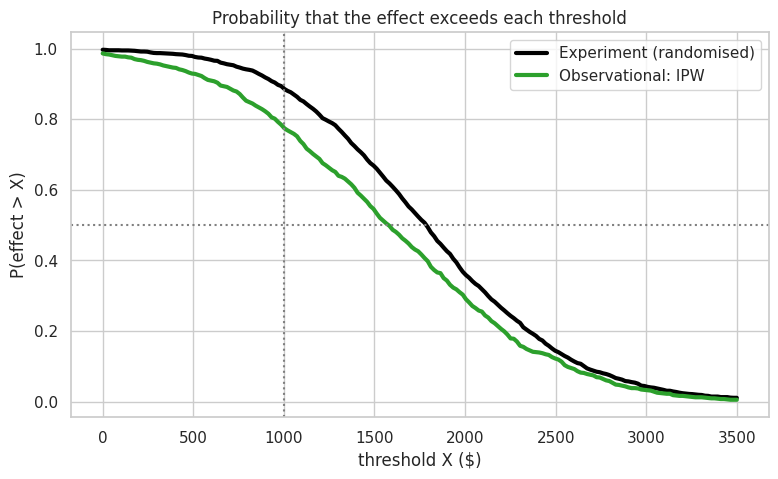

In [44]:
thresholds = np.linspace(0, 3500, 200)
for name, colour in [('Experiment (randomised)', 'black'), ('Observational: IPW', 'tab:green')]:
    plt.plot(thresholds, [(post[name] > t).mean() for t in thresholds], color=colour, lw=3, label=name)
plt.axhline(0.5, color='grey', ls=':'); plt.axvline(1000, color='grey', ls=':')
plt.xlabel('threshold X ($)'); plt.ylabel('P(effect > X)'); plt.legend()
plt.title('Probability that the effect exceeds each threshold');
print(f"P(effect > $1,000): experiment {(post['Experiment (randomised)'] > 1000).mean():.2f} | IPW {(post['Observational: IPW'] > 1000).mean():.2f}")

### How to report a result like this
> "Using weighting to make a comparison group comparable on age, education, background and previous earnings, we estimate that the programme raised 1978 earnings by about \$1,600 per participant (95% credible interval roughly \$160 to \$3,060; probability of a positive effect about 99%). This relies on no unmeasured confounding; previous earnings are the key adjustment."

# Conclusions and Takeaways
---
**Gradient descent**
- Models learn by minimising a loss: step against the slope, θ ← θ − α × slope, until the steps are tiny.
- The **learning rate** matters (too small = slow, too large = diverges); **standardise** features; convex losses (MSE, log-loss) have no local-minimum traps.
- Smarter optimisers (Adam, Newton, L-BFGS) converge in far fewer steps; always check convergence.

**Bayesian modelling**
- Posterior ∝ likelihood × prior. Beta–binomial for rates; normal–normal for averages.
- Credible intervals and probabilities like P(effect > 0) answer the questions people actually ask.
- Always check **prior sensitivity**.

**Causal inference**
- A comparison of groups only estimates a causal effect if the groups are **comparable**; randomisation guarantees it, observational data doesn't.
- Potential outcomes: one is always **missing**; methods differ in how they fill it in.
- Regression adjustment, propensity-score **matching** and **weighting** can remove confounding by measured variables; **check balance** (|SMD| < 0.1) and **overlap**, and state the assumptions.

### Every model and method in this notebook
| Method | Part | What it does | Key visual |
|---|---|---|---|
| Gradient descent (batch) | 2 | Minimises a loss by stepping against the slope | Loss-surface path; learning-rate curves |
| Mini-batch / stochastic GD | 2 | Uses a few rows per step | Noisy loss trace |
| Newton's method | 2 | Uses curvature for faster steps | 7 vs 554 steps |
| Linear regression (OLS) | 2, 5 | Minimises MSE; adjusts for confounders | Convex loss bowl |
| Bayes' theorem | 3 | Flips a conditional probability | Worked example |
| Beta–binomial model | 3 | Posterior for a rate | Posterior curves; difference posterior |
| Normal–normal model | 4 | Posterior for an average effect | Prior sensitivity panels |
| MAP via gradient descent; Ridge = prior | 4 | Posterior peak; regularisation as a prior | GD on the posterior; Ridge vs Bayes |
| Standardised mean differences | 1, 5, 6 | Measures balance | Love plots |
| Regression adjustment | 5 | Controls for confounders in a regression | Scorecard |
| Propensity scores (logistic regression) | 6 | P(treated given background) | Overlap histograms |
| Matching | 6 | Pairs similar people; imputes the missing Y(0) | Balance after matching |
| Inverse-probability weighting | 6 | Re-weights the comparison group | Balance after weighting |
| Sensitivity analysis | 6 | Tests reliance on each confounder | Leave-one-out bars |
| Bayesian bootstrap | 7 | Posterior for any estimate | Posterior comparison; decision curve |

### A reusable checklist for any "did X cause Y?" question
1. Define the **treatment**, the **outcome** and the **population** (and whether you want the ATE or the ATT).
2. List possible **confounders**: what affects both treatment and outcome? Use only variables measured **before** treatment.
3. Estimate the naive difference, then **check balance** (SMD table / love plot).
4. Estimate propensity scores; check **overlap**.
5. Match or weight; **re-check balance**.
6. Estimate the effect, with uncertainty (a confidence or credible interval).
7. Report the result, the assumptions, and a sensitivity check (e.g. different priors, a different propensity model, or dropping a confounder).

## Further reading
- A. Gelman and X.-L. Meng (eds), *Applied Bayesian Modeling and Causal Inference from Incomplete-Data Perspectives* (Wiley, 2004): especially Chapter 3 (Dehejia) on this very dataset.
- R. Dehejia and S. Wahba (1999), "Causal effects in nonexperimental studies", *Journal of the American Statistical Association*.
- S. Cunningham, *Causal Inference: The Mixtape* (free online), chapter on matching and subclassification.